# Wine: PCA, K-Means and t-SNE

In Lab 04 you explored data and practised scaling. Here you will use those skills
to represent wines with fewer coordinates, then inspect groups in those pictures.
The original learning sequence is preserved: **inspect → scale → PCA → K-Means
→ PCA in 3D and explained variance → t-SNE in 2D and 3D**.

## Working instructions
- Save your own copy beside `wine-clustering.csv`.
- Use Python with numpy, pandas, matplotlib, plotly and scikit-learn in Jupyter.
- Run the given imports, then complete each code cell. Seven checkpoints help
  you check understanding along the way: five are self-checks or group discussion;
  only two ask for a brief written answer. Follow the response label at each point.
- The original workflow includes its expected tables and plots, as in last
  year's notebook. These are reference outputs; the work cells are still yours
  to complete and are not presented as having already run.
- Use your code, tables and plots as evidence. Finish with one short critical
  LLM conversation about an existing finding from any part of the notebook.
  No extra chart, separate report or repeated conclusion is required.
- Reuse your EDA and scaling skills. This notebook provides the guided Wine
  examples; the separate Crypto assignment contains the open-ended EDA extension.
- Keep the same observations in the same order throughout the workflow.
- Before submission, restart the kernel, run all completed cells in order and
  save the notebook with your outputs and explanations.

## Understand the data
Each row is one wine sample; the 13 numerical columns describe measurements such
as alcohol, colour intensity and proline. This CSV has no wine-type label column.
We use `k=3` as an illustrative setting, motivated by the source dataset's three
wine types. We are not inferring k here or proving that clusters recover those
types. No known labels enter PCA, K-Means or t-SNE.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

plt.style.use('seaborn-v0_8-darkgrid')


### Load the Wine Data

Load `wine-clustering.csv` as `data`. Display its shape and first five rows.

In [3]:
# Load data, display its shape and preview the first five rows.
data = pd.read_csv('Data/wine-clustering.csv')

display(data.head())

print(data.shape)

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


(178, 13)


### Inspect Data Quality

Report the total missing values,
duplicate-row count and observed data types. Use your Lab 04 skills to decide
whether preparation is needed. Do not delete rows just because a measurement
looks unusual.

In [4]:
# Inspect missing values, duplicate rows and data types.
display(data.isna().sum())
print(f"The amount of duplicated values: {data.duplicated().sum()}")
display(data.dtypes)


Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
dtype: int64

The amount of duplicated values: 0


Alcohol                 float64
Malic_Acid              float64
Ash                     float64
Ash_Alcanity            float64
Magnesium                 int64
Total_Phenols           float64
Flavanoids              float64
Nonflavanoid_Phenols    float64
Proanthocyanins         float64
Color_Intensity         float64
Hue                     float64
OD280                   float64
Proline                   int64
dtype: object

### Checkpoint 1 — Data and Readiness

What does one row represent, and what in your quality checks lets you continue without imputation?

*Self-check / group discussion: no separate written answer required.*

### Scale the Features

The measurements have different
units and spreads. Scaling prevents a feature's numerical scale alone from
dominating distance-based grouping or variance-based projection.

Fit a `StandardScaler` named `SS` to `data`. Store the result as DataFrame `X`,
preserving the column names and row index. Preserve `data` in original units.

In [5]:
# Create SS and the scaled DataFrame X; keep data unchanged.
SS = StandardScaler()
X = pd.DataFrame(
    SS.fit_transform(data),
    index=data.index,
    columns=data.columns
)
X

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,0.876275,2.974543,0.305159,0.301803,-0.332922,-0.985614,-1.424900,1.274310,-0.930179,1.142811,-1.392758,-1.231206,-0.021952
174,0.493343,1.412609,0.414820,1.052516,0.158572,-0.793334,-1.284344,0.549108,-0.316950,0.969783,-1.129518,-1.485445,0.009893
175,0.332758,1.744744,-0.389355,0.151661,1.422412,-1.129824,-1.344582,0.549108,-0.422075,2.224236,-1.612125,-1.485445,0.280575
176,0.209232,0.227694,0.012732,0.151661,1.422412,-1.033684,-1.354622,1.354888,-0.229346,1.834923,-1.568252,-1.400699,0.296498


### Checkpoint 2 — Scaling

After scaling, what changed and what stayed the same? Explain why that matters before the next methods.

*Self-check / group discussion: no separate written answer required.*

### Create Two PCA Coordinates

PCA constructs new axes
as linear combinations of the scaled measurements. It seeks directions that
retain variance; keeping two components leaves some variance out. It does not
select two original columns or preserve every original distance.

Create `pca2` with two components and transform `X` into `X_pca`. Create
`principal_df` with columns `PC1`, `PC2` and the original row index. Display
its shape and first five rows.

In [6]:
# Fit pca2, create X_pca and principal_df, and inspect the result.
pca2 = PCA(n_components=2,random_state=0) 
pca2.fit(X)
X_pca = pca2.transform(X)
X_pca
principal_df = pd.DataFrame(
    {'PCA1':X_pca.T[0],'PCA2':X_pca.T[1]}
)
print(principal_df.shape)
principal_df.head()

(178, 2)


,PCA1,PCA2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


### Checkpoint 3 — PCA Coordinates

What does a row in principal_df represent? Are PC1 and PC2 two original columns selected from data?

*Self-check / group discussion: no separate written answer required.*

### View PCA in 2D

Draw PC1 against PC2 from `principal_df`,
with labelled axes and no group colours yet. A point represents one wine.
Unsupervised learning means that no known target labels were used to fit the
methods; adding colours later does not change that fact.

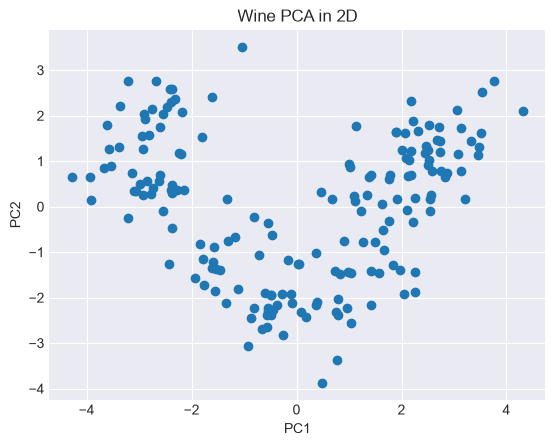

In [7]:
# Plot PC1 versus PC2 without cluster colours.
plt.scatter(x = principal_df.PCA1, y = principal_df.PCA2)
plt.title("Wine PCA in 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

### Create K-Means Groups in the 13-Feature Space

K-Means
alternates between assigning samples to nearby centres and updating the centres
to the means of their assigned samples. The number of groups is supplied as k;
the result is not guaranteed to be the globally best partition.

Fit `kmeans` with `n_clusters=3`, `n_init=15`, `max_iter=500`, `random_state=0`
on **X, the 13 scaled features**, and store its labels as `clusters`. Store its
centres as `centroids`, then project those centres through the fitted `pca2`
into `centroids_pca` for display.

In [8]:
# Fit kmeans on X, save clusters and centroids, then project the centres.
X_k_means = KMeans(n_clusters=3,n_init=15,max_iter=500,random_state=0)
X_k_means.fit(X)

clusters = X_k_means.labels_
centroids = X_k_means.cluster_centers_
centroids_pca = pca2.transform(centroids)


# Calculate counts and percentages
counts = np.bincount(X_k_means.labels_)

# Create the summary table
cluster_table = pd.DataFrame({
    'Cluster': range(len(counts)),
    'Size': counts,
}).set_index('Cluster')

# Display the table
print(cluster_table)

         Size
Cluster      
0          65
1          51
2          62


c:\Users\idanp\anaconda3\envs\labEx5\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


### Checkpoint 4 — Model Input versus Picture

Point to the input used by K-Means. How many features did it use, how many axes are shown in the coloured PCA plot, and what do the colours mean?

*Self-check / group discussion: no separate written answer required.*

### Colour PCA by the Existing Groups

Plot the same PC1
and PC2 coordinates, now coloured by `clusters`. Add the projected centres as
black crosses. These colours show K-Means assignments; they are not known labels.
The model used 13 features even though this picture displays only two axes.

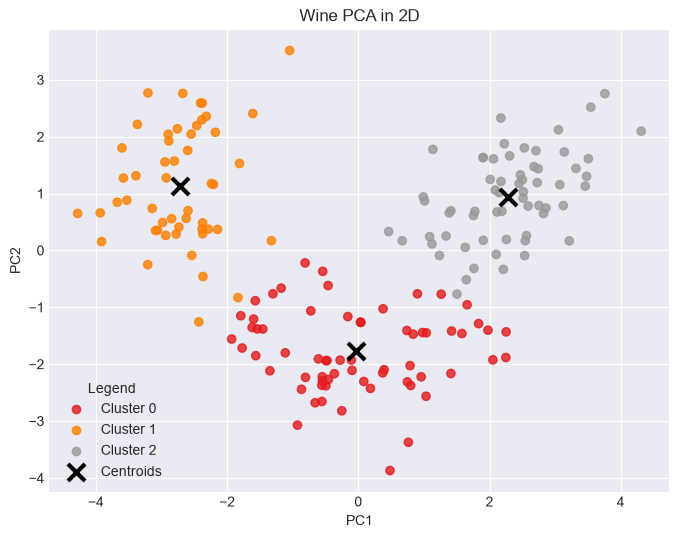

In [9]:
# Colour PC1/PC2 by clusters and add centroids_pca as black crosses.
temp_df = principal_df.copy()
temp_df["cluster"] = clusters

plt.figure(figsize=(8, 6))

# Fix 1: Store the scatter object in a variable ('scatter') to generate the legend later
scatter = plt.scatter(
    x=temp_df.PCA1, 
    y=temp_df.PCA2, 
    c=temp_df.cluster, 
    cmap='Set1', 
    alpha=0.8
)

# Fix 2: Add centroids_pca as black crosses
plt.scatter(
    x=centroids_pca[:, 0], 
    y=centroids_pca[:, 1], 
    color="black", 
    marker="x", 
    s=150, 
    linewidths=3, 
    label="Centroids"  # This label works because it's a single group
)

# Fix 3: Handle the double legend entry (Clusters + Centroids) cleanly
handles, labels = scatter.legend_elements()
centroid_handle = plt.gca().get_legend_handles_labels()[0][-1]

# Combine the individual cluster symbols and the cross symbol into one legend box
plt.legend(
    handles + [centroid_handle], 
    [f"Cluster {l}" for l in labels] + ["Centroids"], 
    title="Legend"
)

plt.title("Wine PCA in 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


### View PCA in 3D

Create `pca3` with three components
and transform the same `X` into `components`. Use a Plotly 3D scatter plot with
the same `clusters` as categorical colours. Rotate the figure to inspect PC3.
This creates another representation of the same samples; do not rerun K-Means.
Keep `pca2` available as the fitted two-component model.

In [10]:
# 1. Fit PCA with 3 components and transform the data
pca3 = PCA(n_components=3, random_state=0)
components = pca3.fit_transform(X)

# 2. Build DataFrame with 3 principal components and existing cluster assignments
principal_df = pd.DataFrame(
    components, 
    columns=['PCA1', 'PCA2', 'PCA3']
)
principal_df["Cluster"] = X_k_means.labels_

# 3. Create interactive 3D scatter plot
fig = px.scatter_3d(
    principal_df,
    x='PCA1',
    y='PCA2',
    z='PCA3',
    color='Cluster',
    title='3D PCA Projection with K-Means Clusters',
    labels={'PCA1': 'PC 1', 'PCA2': 'PC 2', 'PCA3': 'PC 3'},
    opacity=0.8
)

# Optional: Adjust marker size and layout for clearer rotation
fig.update_traces(marker=dict(size=4))
fig.update_layout(
    margin=dict(l=0, r=0, b=0, t=40),
    legend_title_text='Cluster'
)

fig.show()

### Interpret Explained Variance

Fit `pca_var = PCA()`
on `X`. Calculate the cumulative explained-variance ratio and plot it against
the number of components. Use a fraction axis from 0 to 1, with a reference
line at 1. Print the retained percentages for two and three components.

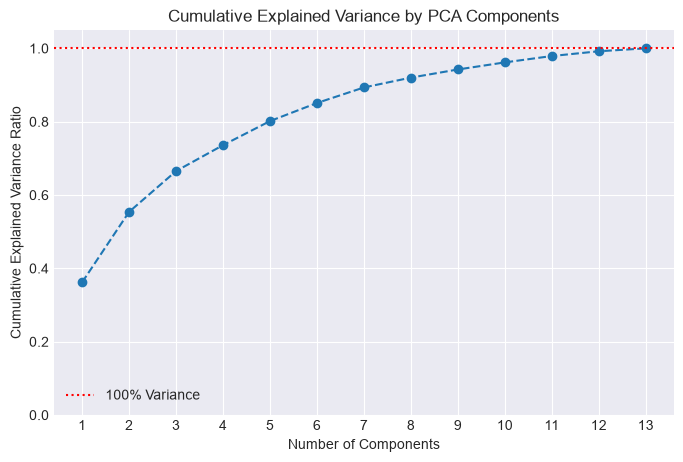

Variance retained by 2 components: 55.41%
Variance retained by 3 components: 66.53%
Variance added by PC3: 11.12%


In [11]:
# Fit pca_var, compute and plot cumulative_variance, then report 2/3-component percentages.
pca_var = PCA()
pca_var.fit(X)

explained_variance = pca_var.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=1.0, color='r', linestyle=':', label='100% Variance')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance Ratio')
plt.ylim(0, 1.05)
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.show()

var_2 = cumulative_variance[1] * 100
var_3 = cumulative_variance[2] * 100

print(f"Variance retained by 2 components: {var_2:.2f}%")
print(f"Variance retained by 3 components: {var_3:.2f}%")
print(f"Variance added by PC3: {(var_3 - var_2):.2f}%")

### Checkpoint 5 — Retained Variance

Use your printed percentages: how much variance is retained by two and three components, and what does PC3 add? Are these percentages an accuracy score?

*Brief written answer: 1–2 sentences, using your own output.*

**Your brief answer:**

_Write 1–2 sentences and point to your result._

Two components retain approximately 55.41% of the total variance, while three components capture 66.53%, meaning PC3 adds about 11.12% of the dataset's variance. These percentages reflect the fraction of total feature variance preserved by linear projection, not an accuracy score for classification or clustering quality.

### Create a 2D t-SNE Representation

t-SNE builds a
nonlinear representation that emphasizes local neighbourhood relationships.
Unlike PCA, its axes are not interpretable linear combinations with explained
variance ratios. Layouts can depend on settings and random initialization;
distances between distant groups in the picture need careful interpretation.

Fit `tsne` with `n_components=2`, `perplexity=30`, `random_state=0`,
`init='random'`, `learning_rate='auto'` on the same `X`, creating `X_tsne`.
Create `tsne_df` with columns `TSNE1` and `TSNE2` and the original row index.
Display its shape and first five rows. No labels enter this fit.

In [15]:
# Fit tsne on X, create X_tsne and tsne_df, and inspect the result.
tsne = TSNE(n_components=2, perplexity=30, random_state=0, init='random', learning_rate='auto')
X_tsne = tsne.fit_transform(X)

tsne_df = pd.DataFrame(
    X_tsne,
    columns=['TSNE1', 'TSNE2'],
    index=X.index
)

print(tsne_df.shape)
display(tsne_df.head())

(178, 2)


,TSNE1,TSNE2
0,-5.086983,-11.623255
1,-4.885348,-7.550381
2,-8.879267,-9.249448
3,-7.819072,-11.900874
4,-9.753020,-5.326407


### Colour t-SNE by the Same K-Means Groups

Plot TSNE1
against TSNE2 and reuse `clusters` for colours. Do not fit another clustering
model. In this scikit-learn implementation t-SNE has no `transform` method for
projecting the original K-Means centres, so do not add those centres as if they
were in t-SNE coordinates.

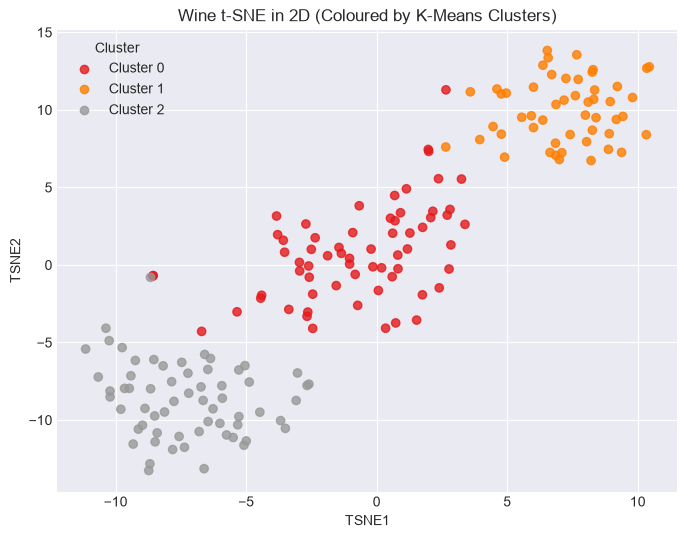

In [16]:
# Plot TSNE1/TSNE2 using the existing clusters as colours.
plt.figure(figsize=(8, 6))
scatter_tsne = plt.scatter(
    x=tsne_df['TSNE1'],
    y=tsne_df['TSNE2'],
    c=clusters,
    cmap='Set1',
    alpha=0.8
)

handles, labels = scatter_tsne.legend_elements()
plt.legend(handles, [f"Cluster {l}" for l in labels], title="Cluster")
plt.title("Wine t-SNE in 2D (Coloured by K-Means Clusters)")
plt.xlabel("TSNE1")
plt.ylabel("TSNE2")
plt.show()

### Checkpoint 6 — t-SNE and Existing Colours

Did t-SNE create new cluster assignments? Explain the origin of its colours and why the original K-Means centres cannot simply be drawn on its axes.

*Self-check / group discussion: no separate written answer required.*

### View t-SNE in 3D

Fit a separate t-SNE with three
components on `X` and save `components_tsne`. Keep `perplexity=30`,
`random_state=0`, `init='random'`, `learning_rate='auto'`. Create a Plotly 3D
scatter with the same categorical `clusters` as colours.

This is a separate embedding, not the 2D result with one extra column added.
Rotate the view and compare it with the PCA picture. With a fixed seed,
repeating the same code is intended to reproduce the layout.

In [17]:
# Fit tsne3, save components_tsne and plot the same clusters in 3D.
tsne3 = TSNE(n_components=3, perplexity=30, random_state=0, init='random', learning_rate='auto')
components_tsne = tsne3.fit_transform(X)

tsne3_df = pd.DataFrame(
    components_tsne,
    columns=['TSNE1', 'TSNE2', 'TSNE3']
)
tsne3_df['Cluster'] = clusters

fig_tsne = px.scatter_3d(
    tsne3_df,
    x='TSNE1',
    y='TSNE2',
    z='TSNE3',
    color='Cluster',
    title='3D t-SNE Embedding with K-Means Clusters',
    labels={'TSNE1': 't-SNE 1', 'TSNE2': 't-SNE 2', 'TSNE3': 't-SNE 3'},
    opacity=0.8
)
fig_tsne.update_traces(marker=dict(size=4))
fig_tsne.update_layout(margin=dict(l=0, r=0, b=0, t=40), legend_title_text='Cluster')
fig_tsne.show()

### Checkpoint 7 — Compare Your Views

Choose one visible difference between your PCA and t-SNE plots. Identify it in your output, and state one conclusion that the pictures alone cannot establish.

*Brief written answer: 1–2 sentences, using your own output.*

**Your brief answer:**

_Write 1–2 sentences and point to your result._

## Closing Discussion — My Reasoning and the LLM's

Choose one finding or conclusion from **any part of this notebook**: data
exploration, scaling, clustering, PCA, or the comparison of representations.
Use an existing chart, table or model result; no new plot or report is needed.

1. **My thinking first:** State your observation and interpretation in 1–2 sentences,
   with a value or a specific feature of your output, before asking the model.
2. **The model's view:** Share that evidence and your interpretation. Ask:
   "Which parts of my interpretation are supported? Give an alternative explanation
   or limitation, in at most three sentences, without code."
3. **My evidence-based verdict:** Compare the replies. What agrees or differs?
   What do you accept or correct in your own claim, the model's claim, both or
   neither, and why? If the evidence is insufficient, say what remains uncertain.

Keep the tool/model name and relevant short reply. Two or three sentences for
your verdict are enough. Agreement needs evidence too; you do not have to find
a model error. One short exchange is enough; a follow-up is optional. Use this
as the closing discussion, not an additional essay. If no LLM is available,
compare your initial interpretation with a plausible alternative you write
yourself and label it the offline alternative.


**My initial interpretation and evidence:**  
In the 2D PCA plot, the three K-Means clusters form distinct groupings, but only retain 55.41% of total variance, which suggests that high-dimensional separation is reasonably well captured linearly, though nearly half of the variance is omitted.

**Tool/model, question and relevant short reply:**  
*Tool/Model:* Gemini  
*Question:* "I observed that 2D PCA captures 55.41% variance and separates the three clusters well. Which parts of my interpretation are supported? Give an alternative explanation or limitation, in at most three sentences, without code."  
*Reply:* "Your observation that two linear components separate the clusters is supported because the leading directions of variance align well with the main between-group differences. However, retaining only 55.4% of variance means subtle non-linear structures and within-cluster variations across the other 11 features are discarded. Consequently, apparent separation in 2D does not guarantee that the original 13D space lacks overlap along the remaining unprojected dimensions."

**What I now accept, correct or cannot decide — and why:**  
I accept the model's limitation that 2D visual separation can be misleading because the remaining 44.59% uncaptured variance could contain feature overlaps not visible on PC1 and PC2. I correct my assumption that good 2D separation implies the full geometry is adequately preserved, as t-SNE and variance curves confirm that high-dimensional structure is richer than a single 2D plane can capture.